<a href="https://colab.research.google.com/github/MAI-AIIU/mathematics-foundation/blob/main/src/sixth-week/matrix-decomposition.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Metadata
**Name**  
> Naveed Ahmad Hematmal

**Assignment**    

> Matrix Decomposition

# Mathematics for Machine Learning

# Laboratory 4: Matrix Decomposition using PyTorch

---

## Topics

1. Determinant and Trace
2. Eigenvalues and Eigenvectors
3. Cholesky Decomposition

Environment

- PyTorch
- NumPy
- Matplotlib
- Seaborn
- Google Colab

---


# Learning Outcomes

After completing this laboratory students should be able to:

✅ Compute determinants

✅ Compute traces

✅ Interpret geometric scaling

✅ Calculate eigenvalues

✅ Calculate eigenvectors

✅ Verify eigendecomposition properties

✅ Perform Cholesky factorization

✅ Apply decomposition methods to Machine Learning

✅ Connect matrix decompositions with PCA

✅ Visualize matrix transformations


In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from matplotlib.patches import Ellipse

torch.set_printoptions(precision=4)

print("PyTorch Version:", torch.__version__)


PyTorch Version: 2.11.0+cu130


# Part A: Determinant and Trace

---

## Theory

For

$$
A \in \mathbb{R}^{n\times n}
$$

the determinant is denoted

$$
\det(A)
$$

For

$$
A=
\begin{bmatrix}
a & b\\
c & d
\end{bmatrix}
$$

$$
\det(A)=ad-bc
$$

### Geometric Interpretation

$$
\text{Area}_{new}
=
|\det(A)| \times \text{Area}_{old}
$$

If

$$
\det(A)=0
$$

the matrix is singular.


In [2]:
A = torch.tensor([
    [2.,1.],
    [3.,4.]
])

print(A)
print("det(A) =", torch.det(A).item())
print("trace(A) =", torch.trace(A).item())


tensor([[2., 1.],
        [3., 4.]])
det(A) = 5.0
trace(A) = 6.0


## Visualization: Determinant as Area Scaling


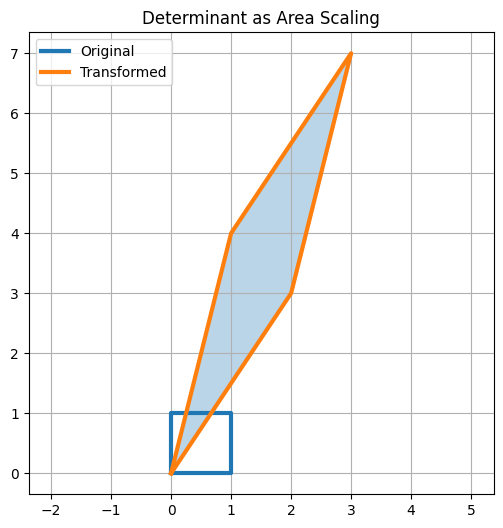

In [3]:
A = np.array([
    [2,1],
    [3,4]
])

square = np.array([
    [0,0],
    [1,0],
    [1,1],
    [0,1],
    [0,0]
])

transformed = square @ A.T

plt.figure(figsize=(6,6))

plt.plot(square[:,0],
         square[:,1],
         linewidth=3,
         label='Original')

plt.plot(transformed[:,0],
         transformed[:,1],
         linewidth=3,
         label='Transformed')

plt.fill(
    transformed[:,0],
    transformed[:,1],
    alpha=0.3
)

plt.axis("equal")
plt.grid()
plt.legend()
plt.title("Determinant as Area Scaling")
plt.show()


## Trace

The trace is

$$
\operatorname{tr}(A)
=
\sum_{i=1}^{n}
a_{ii}
$$

A key property is

$$
\operatorname{tr}(A)
=
\sum_{i=1}^{n}
\lambda_i
$$


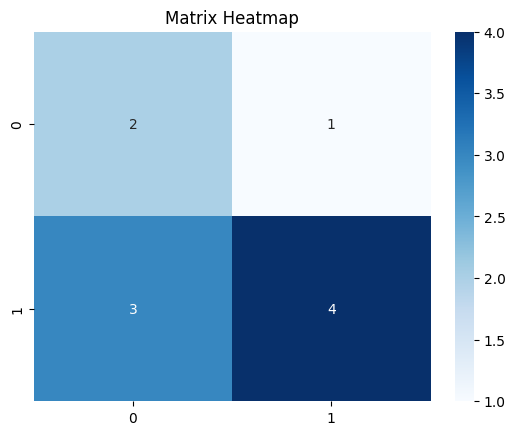

In [4]:
A = np.array([
    [2,1],
    [3,4]
])

sns.heatmap(
    A,
    annot=True,
    cmap="Blues"
)

plt.title("Matrix Heatmap")

plt.show()


# Part B: Eigenvalues and Eigenvectors

## Theory

An eigenvector satisfies

$$
Av=\lambda v
$$

where

$$
v\neq0
$$

and

$$
\lambda
$$

is the corresponding eigenvalue.

The eigenvalues satisfy

$$
\det(A-\lambda I)=0
$$


In [5]:
A = torch.tensor([
    [3.,0.],
    [0.,2.]
])

evals,evecs = torch.linalg.eig(A)

print("Eigenvalues")
print(evals)

print()

print("Eigenvectors")
print(evecs)


Eigenvalues
tensor([3.+0.j, 2.+0.j])

Eigenvectors
tensor([[1.+0.j, 0.+0.j],
        [0.+0.j, 1.+0.j]])


In [6]:
lam = evals[0].real

v = evecs[:,0].real

print(A @ v)

print(lam * v)


tensor([3., 0.])
tensor([3., 0.])


## Eigenvector Visualization


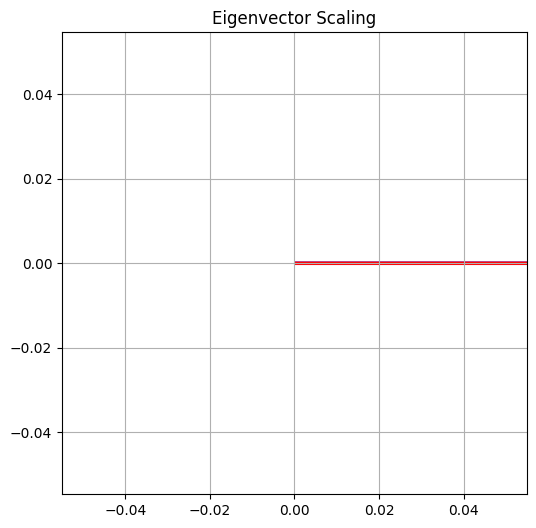

In [7]:
plt.figure(figsize=(6,6))

plt.quiver(
    0,0,
    1,0,
    color='b',
    scale=1,
    scale_units='xy',
    angles='xy'
)

plt.quiver(
    0,0,
    3,0,
    color='r',
    scale=1,
    scale_units='xy',
    angles='xy'
)

plt.grid()
plt.axis('equal')

plt.title("Eigenvector Scaling")

plt.show()


# Part C: Cholesky Decomposition

For a symmetric positive definite matrix

$$
A=A^T
$$

the Cholesky decomposition is

$$
A=LL^T
$$

where

$$
L
$$

is lower triangular.


In [8]:
A = torch.tensor([
    [4.,2.],
    [2.,2.]
])

L = torch.linalg.cholesky(A)

print(L)


tensor([[2., 0.],
        [1., 1.]])


In [9]:
print(L @ L.T)


tensor([[4., 2.],
        [2., 2.]])


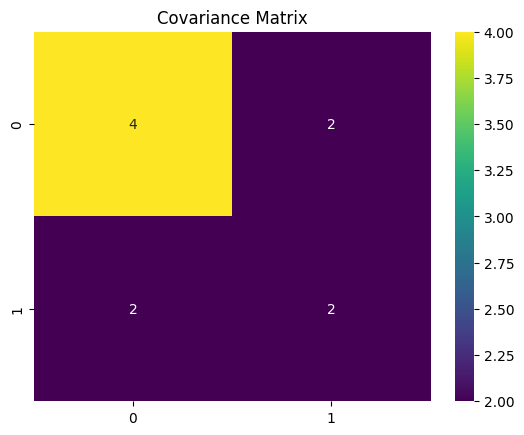

In [10]:
sns.heatmap(
    A.numpy(),
    annot=True,
    cmap='viridis'
)

plt.title("Covariance Matrix")

plt.show()


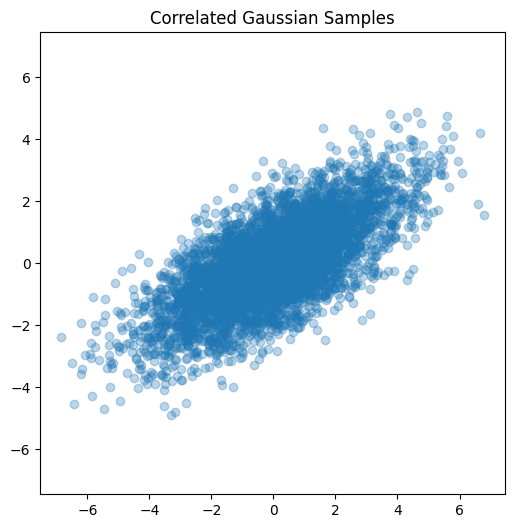

In [11]:
N = 5000

z = torch.randn(N,2)

x = z @ L.T

plt.figure(figsize=(6,6))

plt.scatter(
    x[:,0],
    x[:,1],
    alpha=0.3
)

plt.axis('equal')

plt.title(
    "Correlated Gaussian Samples"
)

plt.show()


In [12]:
A = torch.tensor([
    [25.,15.,-5.],
    [15.,18.,0.],
    [-5.,0.,11.]
])

L = torch.linalg.cholesky(A)

print(L)

print()

print(L @ L.T)


tensor([[ 5.,  0.,  0.],
        [ 3.,  3.,  0.],
        [-1.,  1.,  3.]])

tensor([[25., 15., -5.],
        [15., 18.,  0.],
        [-5.,  0., 11.]])


# Exercise A

Given

A = [[2,4],
     [1,3]]

Compute

1. determinant
2. trace
3. inverse
4. verify A A^{-1} = I


# Exercise B

Find

1. Eigenvalues
2. Eigenvectors

for

[[4,1],
 [2,3]]

Verify

Av = λv


# Exercise C

Compute Cholesky decomposition for

[[25,15,-5],
 [15,18,0],
 [-5,0,11]]

Verify

LLᵀ = A


# Mini Project: PCA from Scratch

Goal:

1. Load Iris Data
2. Standardize Features
3. Compute Covariance Matrix
4. Compute Eigenvalues
5. Determine Principal Components
6. Visualize PCA Projection


## Solution

Exercie A


In [17]:
import numpy as np
# A = [[2,4], [1,3]]
m = torch.tensor([[2, 4], [1, 3]], dtype=torch.float32)
print(m)

tensor([[2., 4.],
        [1., 3.]])


In [18]:
import torch

m_det = torch.linalg.det(m)
print(m_det)
m_trace = torch.trace(m)
print(m_trace)
m_inv = torch.inverse(m)
print(m_inv)
# verify that matrix multiply by its inverse equals to identity matrix
print(m @ m_inv)

tensor(2.)
tensor(5.)
tensor([[ 1.5000, -2.0000],
        [-0.5000,  1.0000]])
tensor([[1., 0.],
        [0., 1.]])


Exercise B

In [31]:
b = torch.tensor([[4, 1], [2, 3]], dtype=torch.float32)
print(b)

tensor([[4., 1.],
        [2., 3.]])


In [32]:
eigenvalues, eigenvectors = torch.linalg.eig(b)
print(eigenvalues)
print(eigenvectors)

tensor([5.0000+0.j, 2.0000+0.j])
tensor([[ 0.7071+0.j, -0.4472+0.j],
        [ 0.7071+0.j,  0.8944+0.j]])


In [36]:
lam = eigenvalues[0]
v = eigenvectors[:, 0]

print(torch.allclose(A.to(v.dtype) @ v, lam * v))

True


Exercise C

In [40]:
c = torch.tensor([[25,15,-5], [15,18,0], [-5,0,11]], dtype=torch.float32)
print(c)

tensor([[25., 15., -5.],
        [15., 18.,  0.],
        [-5.,  0., 11.]])


In [41]:
Cl = torch.linalg.cholesky(c)

print(Cl)
print(Cl @ Cl.T)

tensor([[ 5.,  0.,  0.],
        [ 3.,  3.,  0.],
        [-1.,  1.,  3.]])
tensor([[25., 15., -5.],
        [15., 18.,  0.],
        [-5.,  0., 11.]])


Mini Project: PCA from scrach

Load Iris Data  
Standardize Features  
Compute Covariance Matrix  
Compute Eigenvalues  
Determine Principal Components  
Visualize PCA Projection

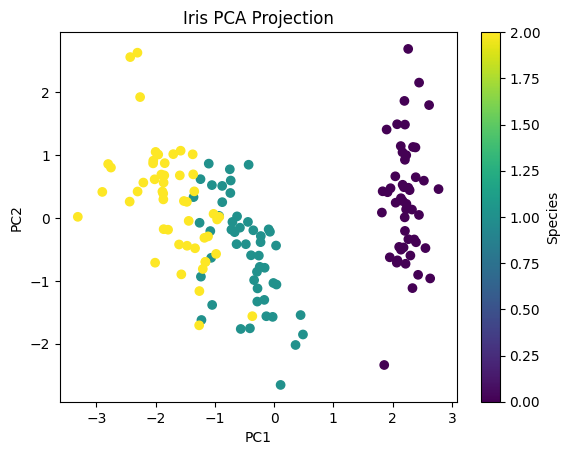

In [43]:
import torch
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler

# 1. Load Iris Data
iris = load_iris()
X = torch.tensor(iris.data, dtype=torch.float32)

# 2. Standardize Features
X = torch.tensor(StandardScaler().fit_transform(X.numpy()), dtype=torch.float32)

# 3. Compute Covariance Matrix
cov = torch.cov(X.T)

# 4. Compute Eigenvalues
eigenvalues, eigenvectors = torch.linalg.eigh(cov)

# 5. Determine Principal Components
indices = torch.argsort(eigenvalues, descending=True)
components = eigenvectors[:, indices[:2]]

X_pca = X @ components

# 7. Visualize PCA Projection
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=iris.target, cmap="viridis")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Iris PCA Projection")
plt.colorbar(label="Species")
plt.show()